# Reproducibility Check: Serena Williams Age Graphic

**Author:** Obaid Nasri

## Overview

This notebook evaluates the computational reproducibility of the New York
Times graphic **"Serena Williams Dominated Her Generation, Then the Next
One, Too"** (Sara Ziegler and Leo Dominguez, Aug. 28, 2022), which plots
every professional match Serena Williams played from age 14 to 40 against
her age relative to each opponent, colored by match outcome.

## Data Source

The underlying data comes from Tennis Abstract's Serena Williams career
match page, specifically the raw javascript data file:

`https://www.tennisabstract.com/jsmatches/SerenaWilliamsCareer.js`

This file is downloaded as-is by `scripts/download_data.py`, parsed and
cleaned by `scripts/clean_data.py` into a tidy `serena` dataset
(`data/processed/serena.csv`), and plotted by `scripts/make_plot.py`.

Serena Williams's date of birth (`26-Sep-1981`) is hardcoded in
`clean_data.py` per the assignment instructions; each opponent's date of
birth is read directly from the raw data file.

## Reproduction

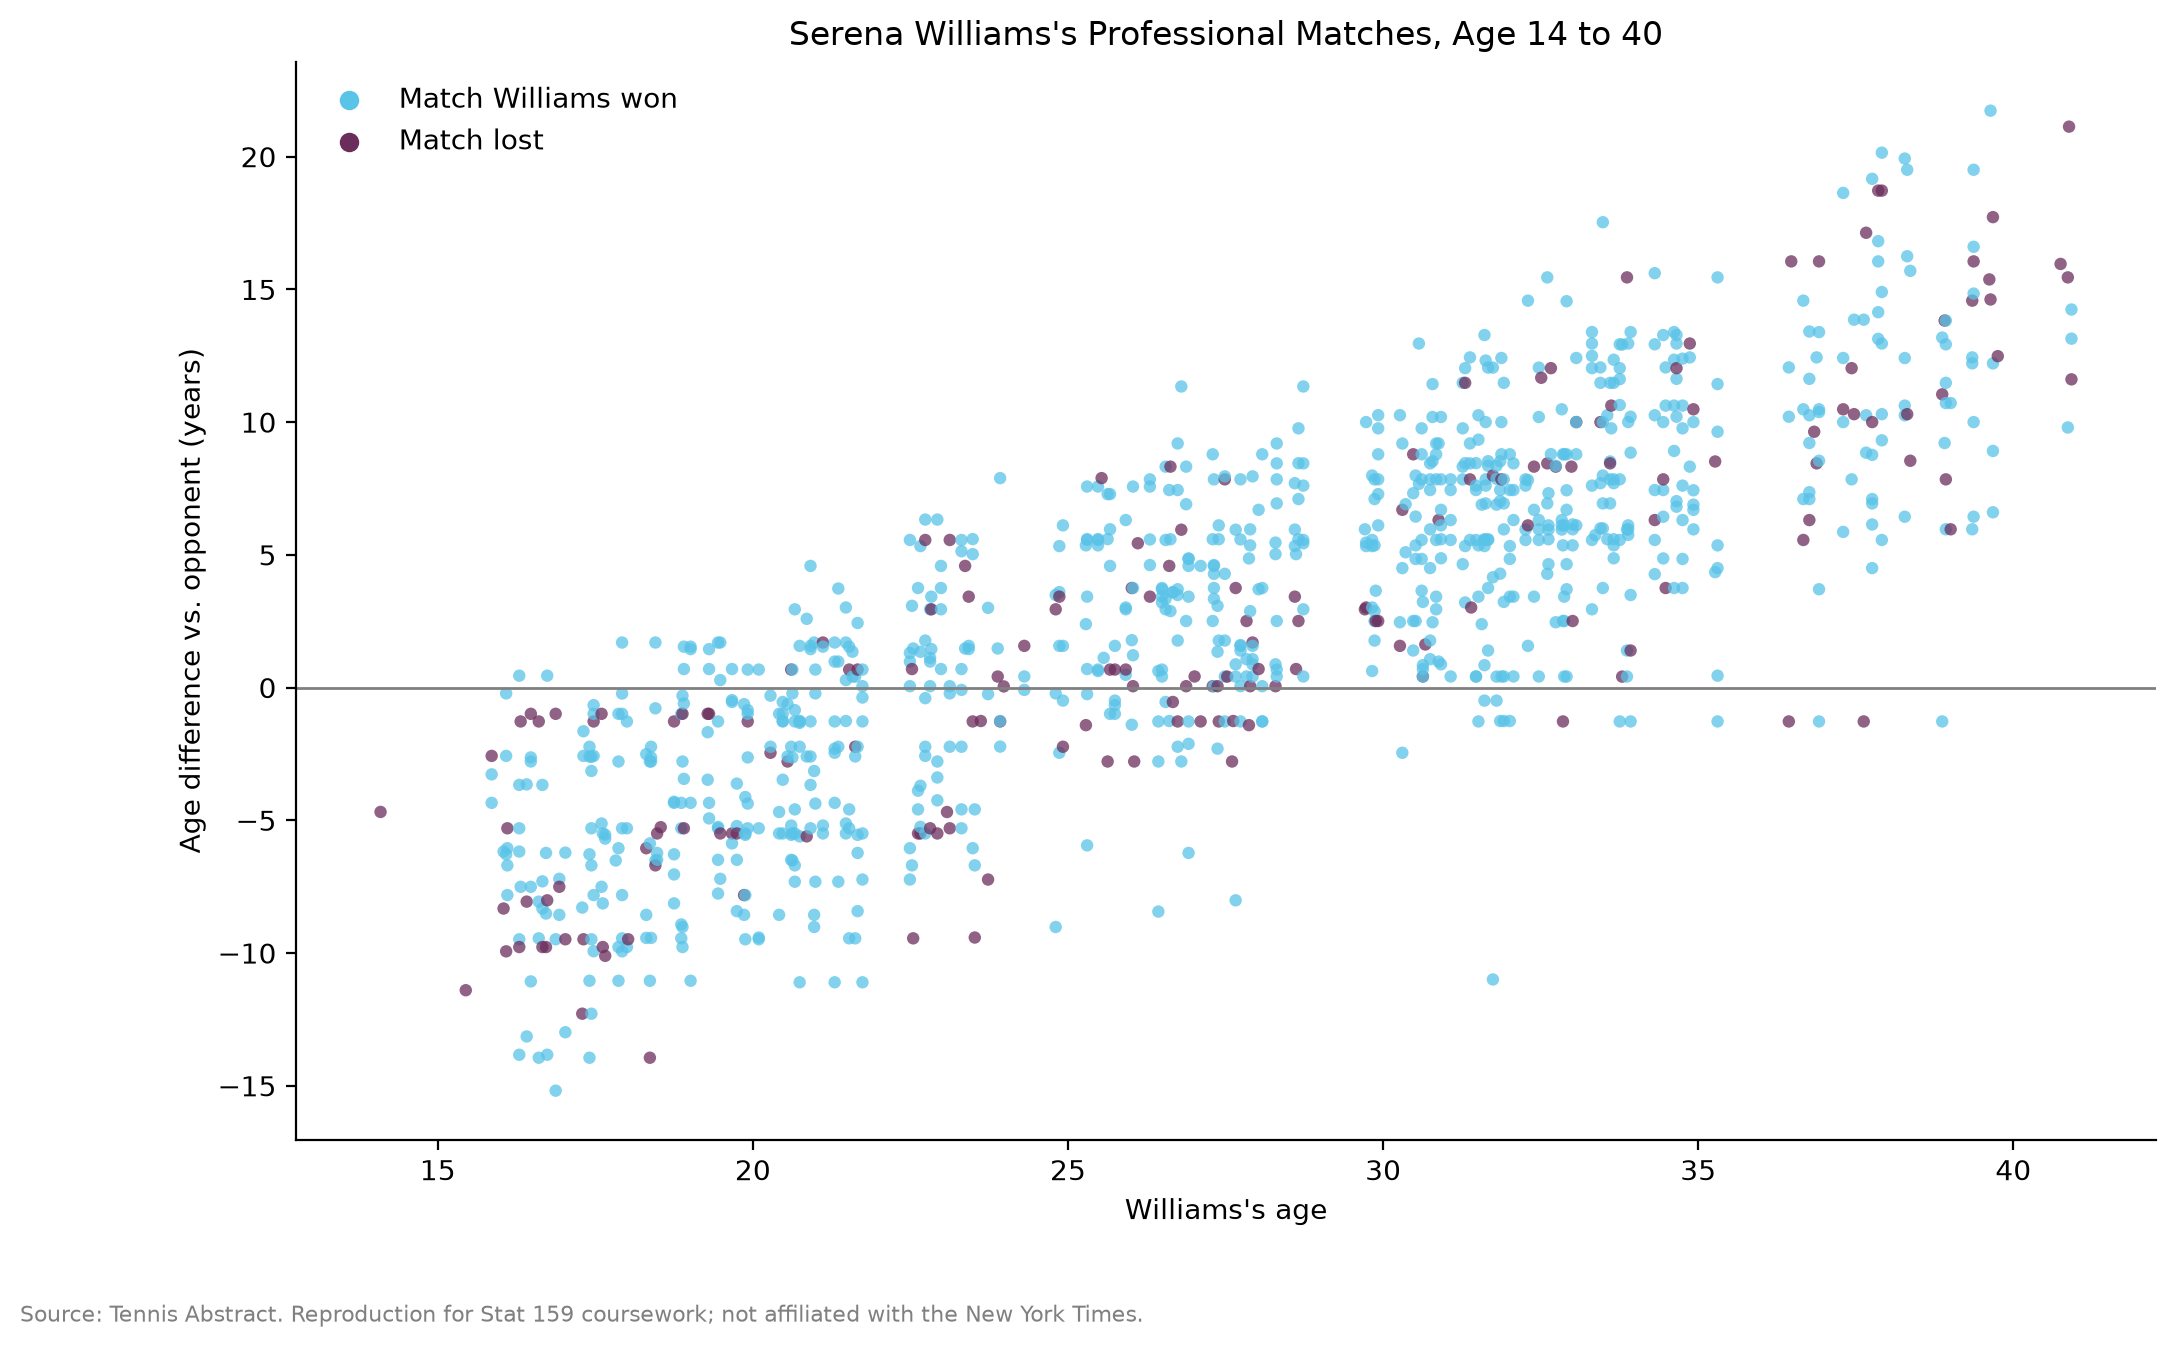

In [1]:
from IPython.display import Image
Image("images/serena_age_plot.png")

## Narrative

The reproduction plots `williams_age` on the x-axis and `age_diff`
(Williams's age minus her opponent's age) on the y-axis, colored by
whether she won or lost the match. This mirrors the three encodings used
in the original NYT graphic. As in the original, matches above the
horizontal reference line are ones where Williams was older than her
opponent, and matches below it are ones where she was younger.

In [1]:
from tennis_package.tennis import _clean_matches

with open("data/raw/SerenaWilliamsCareer.js", "r") as file:
    raw_text = file.read()

serena = _clean_matches(raw_text, "1981-09-26")

serena.head()

,match_date,tournament,surface,opponent_name,result,player_age,opponent_age,age_diff
0,1995-10-30,Canadian Open,Carpet,Anne Miller,L,14.091718,18.776181,-4.684463
1,1997-03-07,Indian Wells,Hard,Alexia Dechaume Balleret,L,15.444216,26.844627,-11.400411
2,1997-08-04,Manhattan Beach,Hard,Magui Serna,L,15.854894,18.428474,-2.573580
3,1997-08-04,Manhattan Beach,Hard,Amanda Basica,W,15.854894,19.123888,-3.268994
4,1997-08-04,Manhattan Beach,Hard,Tamarine Tanasugarn,W,15.854894,20.197125,-4.342231


In [1]:
from tennis_package.tennis import _download_career_data

raw_serena = _download_career_data("Serena Williams")

print(raw_serena[:300])

var morematchmx = [["19951030", "Canadian Open", "Carpet", "W", "L", "", "", "WC", "Q1", "6-1 6-1", "3", "Anne Miller", "149", "7", "", "R", "19770119", "", "USA", "0", "", "", "", "", "", "", "1995-W-WT-CAN-02A-1995-013"],
          ["19970307", "Indian Wells", "Hard", "W", "L", "", "", "WC", "Q1",


In [1]:
from tennis_package.tennis import get_player_matches

serena = get_player_matches("Serena Williams")

serena.head()

,match_date,tournament,surface,opponent_name,result,player_age,opponent_age,age_diff
0,1995-10-30,Canadian Open,Carpet,Anne Miller,L,14.091718,18.776181,-4.684463
1,1997-03-07,Indian Wells,Hard,Alexia Dechaume Balleret,L,15.444216,26.844627,-11.400411
2,1997-08-04,Manhattan Beach,Hard,Magui Serna,L,15.854894,18.428474,-2.573580
3,1997-08-04,Manhattan Beach,Hard,Amanda Basica,W,15.854894,19.123888,-3.268994
4,1997-08-04,Manhattan Beach,Hard,Tamarine Tanasugarn,W,15.854894,20.197125,-4.342231


In [2]:
rafa = get_player_matches("Rafael Nadal")

rafa.head()

,match_date,tournament,surface,opponent_name,result,player_age,opponent_age,age_diff
0,2001-09-10,Spain F10,Hard,Guillermo Platel,L,15.271732,22.264203,-6.992471
1,2001-09-17,Seville CH,Clay,Stefano Galvani,L,15.290897,24.290212,-8.999316
2,2001-09-17,Seville CH,Clay,Israel Matos Gil,W,15.290897,18.759754,-3.468857
3,2001-10-15,Spain 7 4,Clay,Alberto Banus Sado,W,15.367556,27.359343,-11.991786
4,2001-10-15,Spain 7 4,Clay,Juan Giner,L,15.367556,23.216975,-7.849418


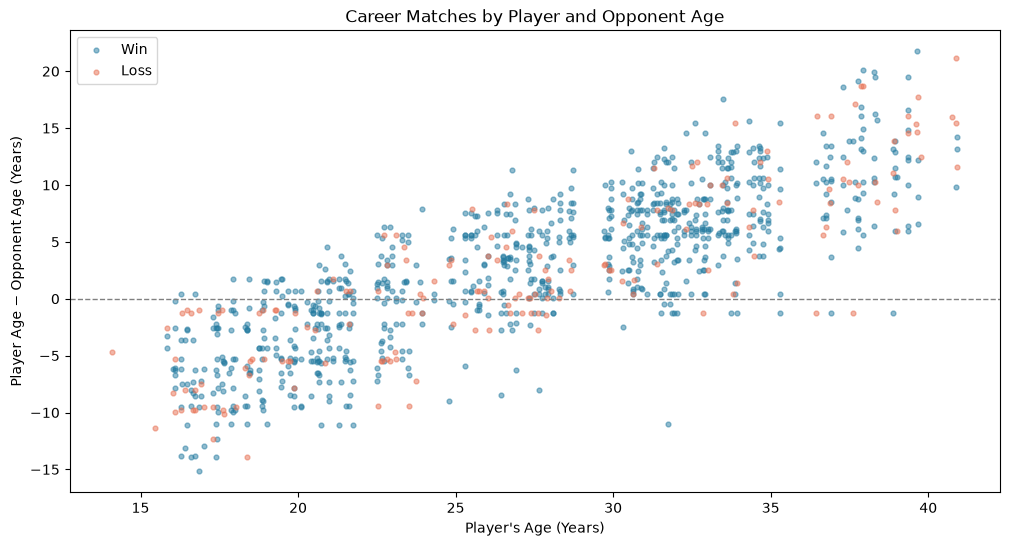

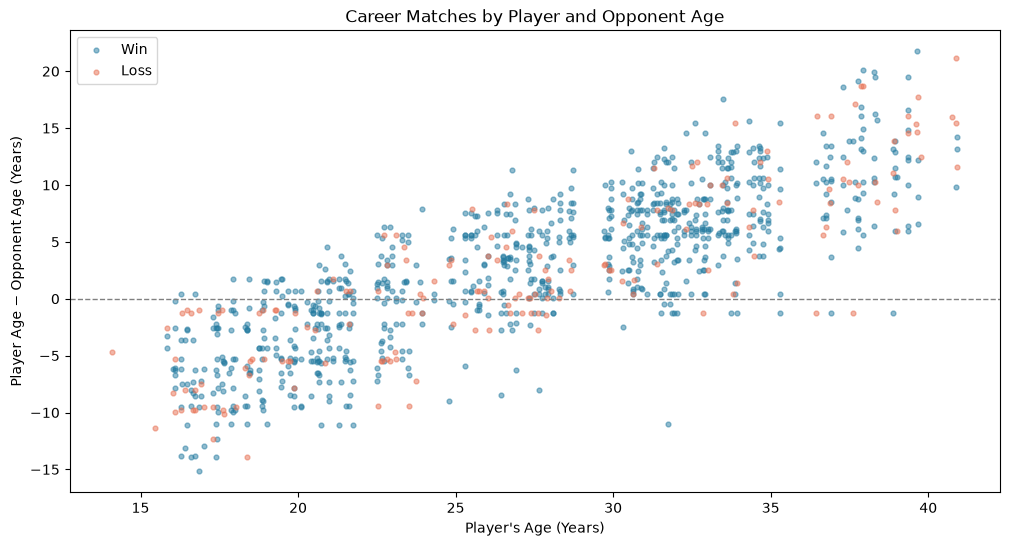

In [1]:
from tennis_package.tennis import get_player_matches, plot_player_matches

serena = get_player_matches("Serena Williams")
plot_player_matches(serena)

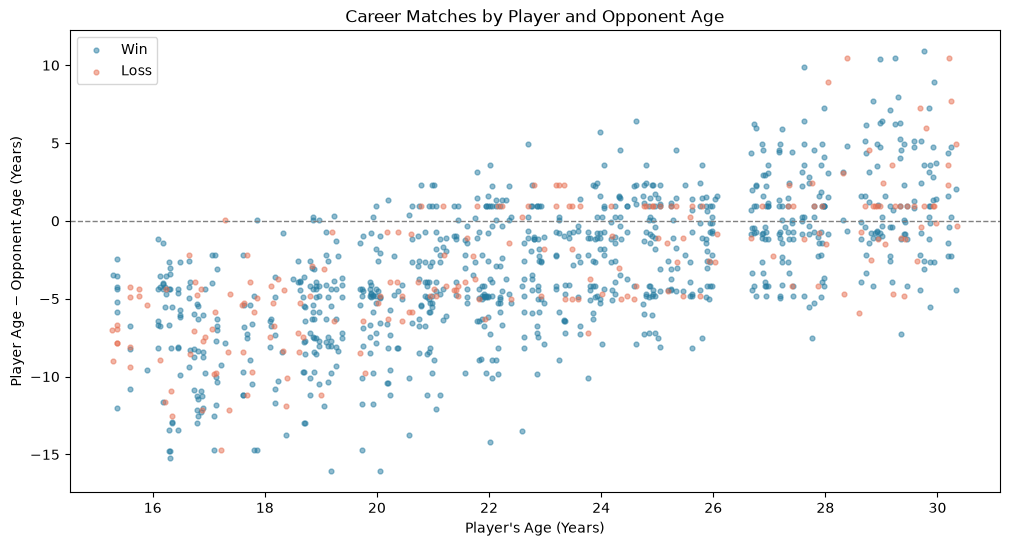

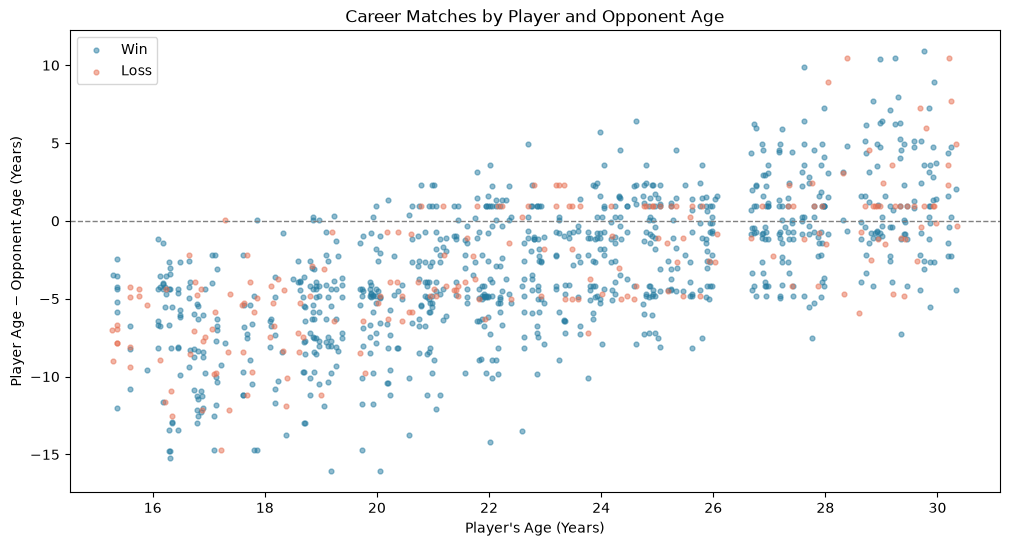

In [2]:
rafa = get_player_matches("Rafael Nadal")
plot_player_matches(rafa)

In [3]:
import urllib.request
import re

url = "https://www.tennisabstract.com/cgi-bin/wplayer.cgi?p=SerenaWilliams"

request = urllib.request.Request(
    url, headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request, timeout=15) as response:
    profile_html = response.read().decode("utf-8", errors="replace")

for match in list(re.finditer(r"born|birth|1981", profile_html, re.I))[:10]:
    print(profile_html[max(0, match.start()-100):match.end()+150])
    print("---")

 currentrank = 1212;
var peakrank = 1;
var peakfirst = 20020708;
var peaklast = 20170508;
var dob = 19810926;
var ht = 175;
var hand = 'R';
var backhand = '2';
var country = 'USA';
var shortlist = 0;
var careerjs = 0;
var active = 1;
var lastdate = 0;
va
---
; // Months are 0-indexed in JS Date
    let day = parseInt(dobString.substring(6, 8), 10);
    let birthDate = new Date(year, month, day);
    let today = new Date();
    let age = today.getFullYear() - birthDate.getFullYear();
    let hasHadBirthdayThis
---
hDate = new Date(year, month, day);
    let today = new Date();
    let age = today.getFullYear() - birthDate.getFullYear();
    let hasHadBirthdayThisYear = (
        today.getMonth() > birthDate.getMonth() || 
        (today.getMonth() === birthDate.get
---
 let today = new Date();
    let age = today.getFullYear() - birthDate.getFullYear();
    let hasHadBirthdayThisYear = (
        today.getMonth() > birthDate.getMonth() || 
        (today.getMonth() === birthDate.getMonth

In [1]:
from tennis_package.tennis import get_player_matches

serena = get_player_matches("Serena Williams")
serena.head()

,match_date,tournament,surface,opponent_name,result,player_age,opponent_age,age_diff
0,1995-10-30,Canadian Open,Carpet,Anne Miller,L,14.091718,18.776181,-4.684463
1,1997-03-07,Indian Wells,Hard,Alexia Dechaume Balleret,L,15.444216,26.844627,-11.400411
2,1997-08-04,Manhattan Beach,Hard,Magui Serna,L,15.854894,18.428474,-2.573580
3,1997-08-04,Manhattan Beach,Hard,Amanda Basica,W,15.854894,19.123888,-3.268994
4,1997-08-04,Manhattan Beach,Hard,Tamarine Tanasugarn,W,15.854894,20.197125,-4.342231


In [2]:
rafa = get_player_matches("Rafael Nadal")
rafa.head()

,match_date,tournament,surface,opponent_name,result,player_age,opponent_age,age_diff
0,2001-09-10,Spain F10,Hard,Guillermo Platel,L,15.271732,22.264203,-6.992471
1,2001-09-17,Seville CH,Clay,Stefano Galvani,L,15.290897,24.290212,-8.999316
2,2001-09-17,Seville CH,Clay,Israel Matos Gil,W,15.290897,18.759754,-3.468857
3,2001-10-15,Spain 7 4,Clay,Alberto Banus Sado,W,15.367556,27.359343,-11.991786
4,2001-10-15,Spain 7 4,Clay,Juan Giner,L,15.367556,23.216975,-7.849418


In [1]:
from tennis_package.tennis import get_player_matches, plot_player_matches

venus = get_player_matches("Venus Williams")

venus.head()

,match_date,tournament,surface,opponent_name,result,player_age,opponent_age,age_diff
0,1994-10-31,Oakland,Carpet,Arantxa Sanchez Vicario,L,14.370979,22.869268,-8.498289
1,1994-10-31,Oakland,Carpet,Shaun Stafford,W,14.370979,25.880903,-11.509925
2,1995-08-07,Manhattan Beach,Hard,Asa Svensson,L,15.137577,20.142368,-5.004791
3,1995-08-14,Canadian Open,Hard,Sabine Appelmans,L,15.156742,23.310062,-8.153320
4,1995-10-30,Oakland,Carpet,Magdalena Maleeva,L,15.367556,20.580424,-5.212868


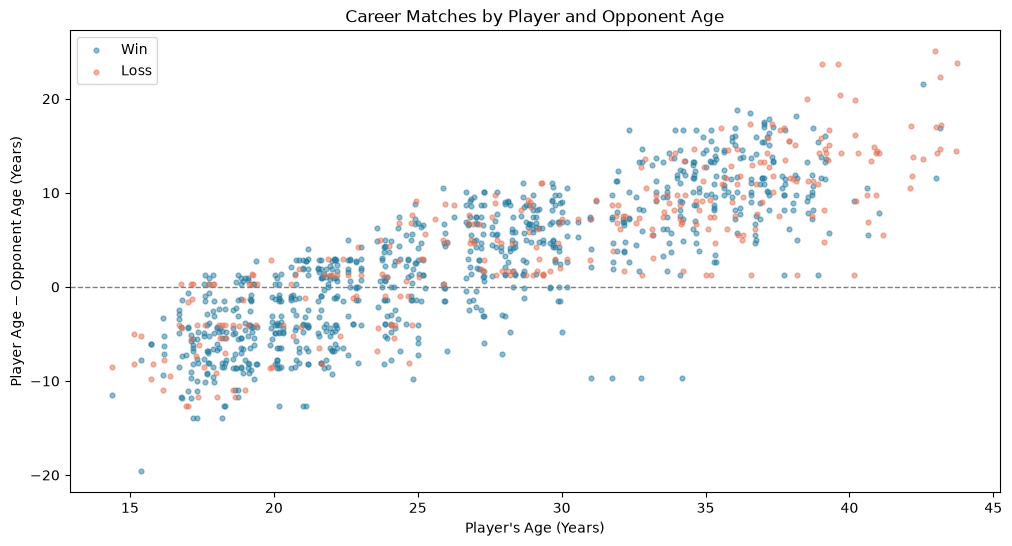

In [2]:
plot_player_matches(venus);

In [3]:
get_player_matches("Invalid Player")

ValueError: Player 'Invalid Player' was not found.